# importing all the libraries

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

from warnings import filterwarnings
filterwarnings(action='ignore')

# loading the dataset

In [ ]:
df = pd.read_csv('/content/Heart_Disease_Prediction.csv')

In [ ]:
# viewing first 5 rows
df.head()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence


In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='Reds', fmt=".2f")
plt.title("Correlation Heatmap of Features")
plt.show()

ValueError: could not convert string to float: 'Presence'

<Figure size 1200x800 with 0 Axes>

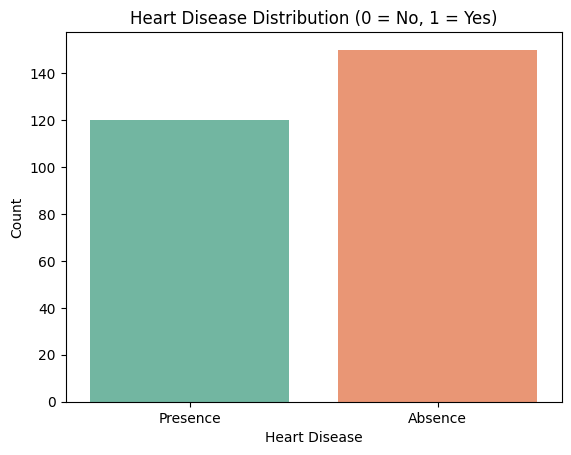

In [ ]:
sns.countplot(x='Heart Disease', data=df, palette='Set2')
plt.title("Heart Disease Distribution (0 = No, 1 = Yes)")
plt.xlabel("Heart Disease")
plt.ylabel("Count")
plt.show()


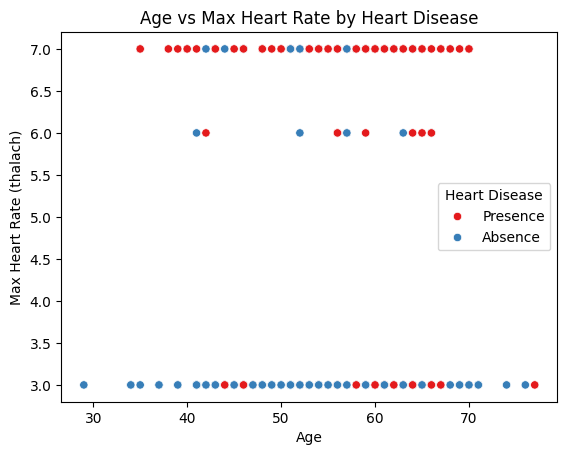

In [ ]:
sns.scatterplot(x='Age', y='Thallium', hue='Heart Disease', data=df, palette='Set1')
plt.title("Age vs Max Heart Rate by Heart Disease")
plt.xlabel("Age")
plt.ylabel("Max Heart Rate (thalach)")
plt.show()


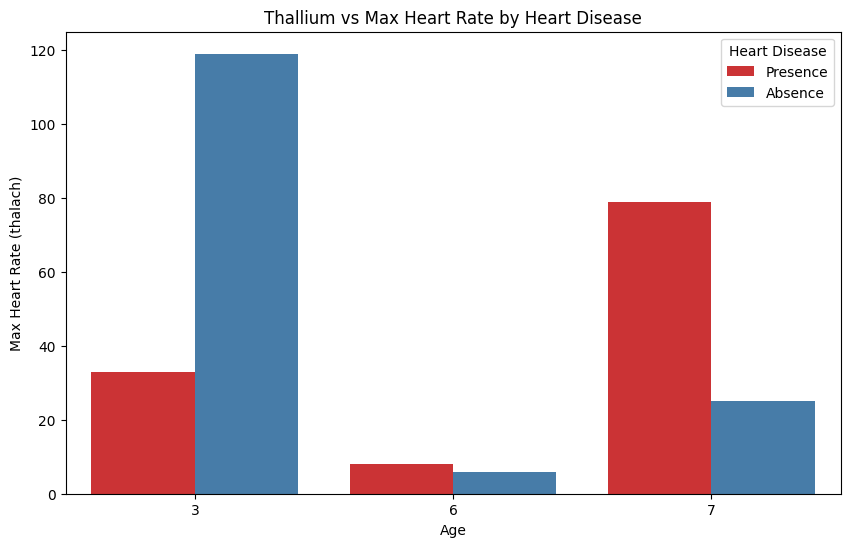

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(x='Thallium', hue='Heart Disease', data=df, palette='Set1')
plt.title("Thallium vs Max Heart Rate by Heart Disease")
plt.xlabel("Age")
plt.ylabel("Max Heart Rate (thalach)")
plt.show()


In [ ]:
 # checking null values in dataset
df.isnull().sum()

,0
Age,0
Sex,0
Chest pain type,0
BP,0
Cholesterol,0
FBS over 120,0
EKG results,0
Max HR,0
Exercise angina,0
ST depression,0


In [ ]:
df.shape

(270, 14)

In [ ]:
df.describe()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium
count,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.00000,270.000000,270.000000,270.000000
mean,54.433333,0.677778,3.174074,131.344444,249.659259,0.148148,1.022222,149.677778,0.329630,1.05000,1.585185,0.670370,4.696296
std,9.109067,0.468195,0.950090,17.861608,51.686237,0.355906,0.997891,23.165717,0.470952,1.14521,0.614390,0.943896,1.940659
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.00000,1.000000,0.000000,3.000000
25%,48.000000,0.000000,3.000000,120.000000,213.000000,0.000000,0.000000,133.000000,0.000000,0.00000,1.000000,0.000000,3.000000
50%,55.000000,1.000000,3.000000,130.000000,245.000000,0.000000,2.000000,153.500000,0.000000,0.80000,2.000000,0.000000,3.000000
75%,61.000000,1.000000,4.000000,140.000000,280.000000,0.000000,2.000000,166.000000,1.000000,1.60000,2.000000,1.000000,7.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.20000,3.000000,3.000000,7.000000


In [ ]:
df['Heart Disease'].value_counts()

,count
Heart Disease,
Absence,150
Presence,120


# person having disease : 1
# no disease : 0

In [ ]:
df['Heart Disease'] = df['Heart Disease'].replace({'Presence' : 1, 'Absence' : 0})

In [ ]:
x = df.drop(columns='Heart Disease', axis=1)
y = df['Heart Disease']

In [ ]:
print(x)

     Age  Sex  Chest pain type  ...  Slope of ST  Number of vessels fluro  Thallium
0     70    1                4  ...            2                        3         3
1     67    0                3  ...            2                        0         7
2     57    1                2  ...            1                        0         7
3     64    1                4  ...            2                        1         7
4     74    0                2  ...            1                        1         3
..   ...  ...              ...  ...          ...                      ...       ...
265   52    1                3  ...            1                        0         7
266   44    1                2  ...            1                        0         7
267   56    0                2  ...            2                        0         3
268   57    1                4  ...            2                        0         6
269   67    1                4  ...            2                        3   

In [ ]:
print(y)

0      1
1      0
2      1
3      0
4      0
      ..
265    0
266    0
267    0
268    0
269    1
Name: Heart Disease, Length: 270, dtype: int64


In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,stratify=y,random_state=2)

In [ ]:
print(x.shape, x_train.shape, x_test.shape)

(270, 13) (216, 13) (54, 13)


In [ ]:
model = LogisticRegression()

In [ ]:
model.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=3, min_samples_leaf=2, random_state=2)

# Model Evaluation

In [ ]:
x_train_pred = model.predict(x_train)
training_data_accuracy = accuracy_score(x_train_pred, y_train)

In [ ]:
print("training_data_accuracy", training_data_accuracy)

training_data_accuracy 0.8842592592592593


In [ ]:
x_test_pred = model.predict(x_test)
test_data_accuracy = accuracy_score(x_test_pred, y_test)
print("test_data_accuracy", test_data_accuracy)

test_data_accuracy 0.7407407407407407


# Prediction

In [ ]:
input_data = (67,0,3,115,564,0,2,160,0,1.6,2,0,7)
input_data_array = np.asarray(input_data)
# reshape bcz we predict only one instance
input_data_reshaped = input_data_array.reshape(1,-1)

prediction = model.predict(input_data_reshaped)
print(prediction)

if prediction[0] == 0:
  print("The person does not have Heart Disease")
else:
  print("The person has Heart Disease")

[0]
The person does not have Heart Disease


# For deployment on streamlit


In [ ]:
# import pickle

In [ ]:
# with open('model.pkl', 'wb') as files:
  # pickle.dump(model, files)